# 03 Tree models across F0, F1 and F2

Step 9. Run `.venv/bin/python -m src.train_trees` first. This notebook only reads the experiment log and selected configurations; it never fits models. The V-column list remains provisional.

Time CV uses seed 0: 20 LightGBM configurations per feature set, four Random Forest configurations, and four logistic-regression C values. Each chosen configuration is evaluated on validation with seeds 0, 1 and 2. LightGBM uses average-precision early stopping on the fold validation part (or the main validation block during the final fit). Thresholds are also selected on validation, so its precision/recall estimates are optimistic. Test scoring is reserved until experiment freeze.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import ROOT
from src.experiment import logged_run
from src.results import LOG_PATH

log = pd.read_csv(LOG_PATH)
config = yaml.safe_load((ROOT / 'config' / 'best_params.yaml').read_text())
models = ['logreg', 'rf', 'lgbm']
feature_sets = ['F0', 'F1', 'F2']
rows = []
for model in models:
    for feature_set in feature_sets:
        params = config['models'][model][feature_set]['params']
        for seed in (0, 1, 2):
            row = logged_run(model, feature_set, 'val', seed, params)
            assert row is not None, (model, feature_set, seed)
            rows.append(row)
val = pd.DataFrame(rows)
assert len(val) == 27
assert not log['split'].eq('test').any(), 'test block must stay unscored before freeze'
print(f'{len(log)} logged fits; {len(val)} selected validation runs; no test scoring')

363 logged fits; 27 selected validation runs; no test scoring


## Validation metrics (mean and sample standard deviation over three seeds)

In [2]:
summary = val.groupby(['model', 'feature_set']).agg(
    pr_auc_mean=('pr_auc', 'mean'), pr_auc_std=('pr_auc', 'std'),
    auroc_mean=('auroc', 'mean'), auroc_std=('auroc', 'std'),
    recall_top1pct_mean=('recall_top1pct', 'mean'),
    recall_top1pct_std=('recall_top1pct', 'std'),
    runtime_s_mean=('runtime_s', 'mean'), runtime_s_min=('runtime_s', 'min'),
    runtime_s_max=('runtime_s', 'max'), seeds=('seed', 'nunique'))
assert summary['seeds'].eq(3).all()
summary.round(6)

pr_auc_mean  pr_auc_std  auroc_mean  auroc_std  \
model  feature_set                                                   
lgbm   F0              0.621505    0.003524    0.924754   0.000928   
       F1              0.645580    0.002861    0.923572   0.000999   
       F2              0.654117    0.002064    0.929875   0.001157   
logreg F0              0.343849    0.000000    0.834750   0.000000   
       F1              0.345514    0.000000    0.838332   0.000000   
       F2              0.347050    0.000000    0.840709   0.000000   
rf     F0              0.452248    0.001699    0.890024   0.001487   
       F1              0.465774    0.002072    0.899685   0.000104   
       F2              0.464473    0.000569    0.898213   0.000211   

                    recall_top1pct_mean  recall_top1pct_std  runtime_s_mean  \
model  feature_set                                                            
lgbm   F0                      0.293715            0.001248      130.490000   
       F1                      0.300918            0.001871      160.023333   
       F2                      0.300378            0.000540      198.236667   
logreg F0                      0.201513            0.000000       98.176667   
       F1                      0.202593            0.000000      104.113333   
       F2                      0.202593            0.000000       55.753333   
rf     F0                      0.258239            0.001621      109.403333   
       F1                      0.258059            0.002183      191.616667   
       F2                      0.259679            0.001360      122.976667   

                    runtime_s_min  runtime_s_max  seeds  
model  feature_set                                       
lgbm   F0                  110.64         156.99      3  
       F1                  145.77         176.49      3  
       F2                  151.32         226.72      3  
logreg F0                   65.17         142.14      3  
       F1                   83.20         131.43      3  
       F2                   55.00          56.21      3  
rf     F0                   98.47         130.70      3  
       F1                  157.12         259.48      3  
       F2                  110.73         144.92      3

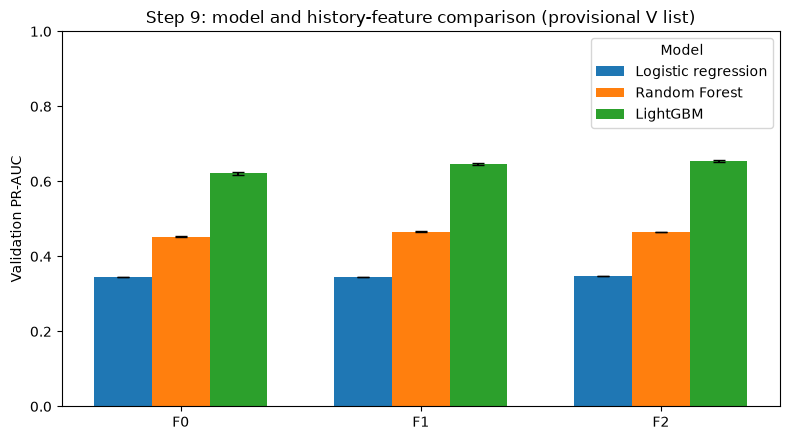

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(feature_sets))
width = 0.24
labels = {'logreg': 'Logistic regression', 'rf': 'Random Forest', 'lgbm': 'LightGBM'}
for i, model in enumerate(models):
    subset = summary.loc[model].reindex(feature_sets)
    ax.bar(x + (i - 1) * width, subset.pr_auc_mean, width,
           yerr=subset.pr_auc_std, capsize=4, label=labels[model])
ax.set_xticks(x, feature_sets)
ax.set_ylim(0, 1)
ax.set_ylabel('Validation PR-AUC')
ax.set_title('Step 9: model and history-feature comparison (provisional V list)')
ax.legend(title='Model')
fig.tight_layout()
path = ROOT / 'reports' / 'figures' / 'trees_validation.png'
path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(path, dpi=150)
plt.show()

## Selected configurations and per-fit outcomes

`params._fit` records LightGBM best iteration and its training-only class weight; `threshold` was selected on validation.

In [4]:
val[['model', 'feature_set', 'seed', 'params', 'pr_auc', 'auroc', 'precision', 'recall', 'recall_top1pct', 'runtime_s']]

,model,feature_set,seed,params,pr_auc,auroc,precision,recall,recall_top1pct,runtime_s
0,logreg,F0,0,"{""C"": 0.1, ""threshold"": 0.8995620012283325}",0.343849,0.834750,0.446319,0.314425,0.201513,65.17
1,logreg,F0,1,"{""C"": 0.1, ""threshold"": 0.8995620012283325}",0.343849,0.834750,0.446319,0.314425,0.201513,87.22
2,logreg,F0,2,"{""C"": 0.1, ""threshold"": 0.8995620012283325}",0.343849,0.834750,0.446319,0.314425,0.201513,142.14
3,logreg,F1,0,"{""C"": 0.1, ""threshold"": 0.8961949348449707}",0.345514,0.838332,0.413389,0.323609,0.202593,131.43
4,logreg,F1,1,"{""C"": 0.1, ""threshold"": 0.8961949348449707}",0.345514,0.838332,0.413389,0.323609,0.202593,97.71
5,logreg,F1,2,"{""C"": 0.1, ""threshold"": 0.8961949348449707}",0.345514,0.838332,0.413389,0.323609,0.202593,83.20
6,logreg,F2,0,"{""C"": 0.1, ""threshold"": 0.9013215899467468}",0.347050,0.840709,0.422585,0.321448,0.202593,55.00
7,logreg,F2,1,"{""C"": 0.1, ""threshold"": 0.9013215899467468}",0.347050,0.840709,0.422585,0.321448,0.202593,56.05
8,logreg,F2,2,"{""C"": 0.1, ""threshold"": 0.9013215899467468}",0.347050,0.840709,0.422585,0.321448,0.202593,56.21
9,rf,F0,0,"{""max_depth"": 24, ""min_samples_leaf"": 20, ""thr...",0.454189,0.891738,0.600000,0.354943,0.259860,130.70


## Time-CV search results

Each row below is one candidate averaged across the four time folds. Fold-to-fold variation measures temporal variation; it differs from the seed variation above.

In [5]:
cv = log[(log.split == 'cv') & (log.cv_scheme == 'time') & (log.seed == 0)
         & log.model.isin(models) & log.feature_set.isin(feature_sets)].copy()
cv['candidate'] = cv.params.map(lambda p: json.dumps(
    {k: v for k, v in json.loads(p).items() if k not in ('fold', '_fit')}, sort_keys=True))
cv_summary = cv.groupby(['model', 'feature_set', 'candidate']).agg(
    pr_auc_mean=('pr_auc', 'mean'), pr_auc_std=('pr_auc', 'std'),
    runtime_s_mean=('runtime_s', 'mean'), folds=('pr_auc', 'count'))
assert cv_summary.folds.eq(4).all()
assert len(cv_summary) == 3 * (20 + 4 + 4)
cv_summary.round(6)

pr_auc_mean  \
model feature_set candidate                                                         
lgbm  F0          {"learning_rate": 0.03, "min_child_samples": 10...     0.602270   
                  {"learning_rate": 0.03, "min_child_samples": 10...     0.625402   
                  {"learning_rate": 0.03, "min_child_samples": 10...     0.619845   
                  {"learning_rate": 0.03, "min_child_samples": 20...     0.598432   
                  {"learning_rate": 0.03, "min_child_samples": 20...     0.618426   
...                                                                           ...   
rf    F1          {"max_depth": 24, "min_samples_leaf": 5}               0.535915   
      F2          {"max_depth": 12, "min_samples_leaf": 20}              0.504876   
                  {"max_depth": 12, "min_samples_leaf": 5}               0.492426   
                  {"max_depth": 24, "min_samples_leaf": 20}              0.537425   
                  {"max_depth": 24, "min_samples_leaf": 5}               0.533815   

                                                                      pr_auc_std  \
model feature_set candidate                                                        
lgbm  F0          {"learning_rate": 0.03, "min_child_samples": 10...    0.040261   
                  {"learning_rate": 0.03, "min_child_samples": 10...    0.040237   
                  {"learning_rate": 0.03, "min_child_samples": 10...    0.042607   
                  {"learning_rate": 0.03, "min_child_samples": 20...    0.034452   
                  {"learning_rate": 0.03, "min_child_samples": 20...    0.038548   
...                                                                          ...   
rf    F1          {"max_depth": 24, "min_samples_leaf": 5}              0.023713   
      F2          {"max_depth": 12, "min_samples_leaf": 20}             0.016111   
                  {"max_depth": 12, "min_samples_leaf": 5}              0.026072   
                  {"max_depth": 24, "min_samples_leaf": 20}             0.015652   
                  {"max_depth": 24, "min_samples_leaf": 5}              0.021185   

                                                                      runtime_s_mean  \
model feature_set candidate                                                            
lgbm  F0          {"learning_rate": 0.03, "min_child_samples": 10...         99.7125   
                  {"learning_rate": 0.03, "min_child_samples": 10...         61.1050   
                  {"learning_rate": 0.03, "min_child_samples": 10...         66.2075   
                  {"learning_rate": 0.03, "min_child_samples": 20...         90.5925   
                  {"learning_rate": 0.03, "min_child_samples": 20...         58.0275   
...                                                                              ...   
rf    F1          {"max_depth": 24, "min_samples_leaf": 5}                   79.3025   
      F2          {"max_depth": 12, "min_samples_leaf": 20}                  43.1025   
                  {"max_depth": 12, "min_samples_leaf": 5}                   39.4100   
                  {"max_depth": 24, "min_samples_leaf": 20}                  66.0825   
                  {"max_depth": 24, "min_samples_leaf": 5}                   69.7400   

                                                                      folds  
model feature_set candidate                                                  
lgbm  F0          {"learning_rate": 0.03, "min_child_samples": 10...      4  
                  {"learning_rate": 0.03, "min_child_samples": 10...      4  
                  {"learning_rate": 0.03, "min_child_samples": 10...      4  
                  {"learning_rate": 0.03, "min_child_samples": 20...      4  
                  {"learning_rate": 0.03, "min_child_samples": 20...      4  
...                                                                     ...  
rf    F1          {"max_depth": 24, "min_samples_leaf": 5}                4  
      F2          {"max_